In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing & Splitting
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE

# 4 Algoritma Klasifikasi
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

# Evaluasi & Feature Importance
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)
from sklearn.inspection import permutation_importance

# Konfigurasi tampilan tabel pandas
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

# 2. Load Data, Preprocessing, dan Penanganan Imbalanced (SMOTE)

Bagian ini membersihkan duplikat, melakukan One-Hot Encoding pada kolom kategorikal (gender dan smoking_history), membagi data latih-uji, dan menyeimbangkan kelas latih menggunakan SMOTE.

In [2]:
# 1. Load Dataset
df = pd.read_csv('diabetes_prediction_dataset.csv')
print(f"Ukuran dataset awal: {df.shape}")

# 2. Hapus data duplikat agar tidak terjadi data leakage
df = df.drop_duplicates().reset_index(drop=True)
print(f"Ukuran setelah hapus duplikat: {df.shape}")

# 3. Encoding fitur kategorikal ('gender' dan 'smoking_history')
df_encoded = pd.get_dummies(df, columns=['gender', 'smoking_history'], drop_first=True, dtype=int)

# Pisahkan fitur (X) dan target (y)
X = df_encoded.drop(columns=['diabetes'])
y = df_encoded['diabetes']

# 4. Train-Test Split (80% Train, 20% Test) dengan Stratified Sampling
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("\nDistribusi kelas pada Data Latih (Sebelum SMOTE):")
print(y_train.value_counts())

# 5. Penanganan Imbalanced Data menggunakan SMOTE (Hanya pada Data Latih!)
smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

print("\nDistribusi kelas pada Data Latih (Sesudah SMOTE):")
print(y_train_res.value_counts())

Ukuran dataset awal: (100000, 9)
Ukuran setelah hapus duplikat: (96146, 9)

Distribusi kelas pada Data Latih (Sebelum SMOTE):
diabetes
0    70130
1     6786
Name: count, dtype: int64



Distribusi kelas pada Data Latih (Sesudah SMOTE):
diabetes
0    70130
1    70130
Name: count, dtype: int64


# 3. Pemodelan dan Evaluasi Masing-Masing Algoritma

## A. Decision Tree

In [3]:
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train_res, y_train_res)

y_pred_dt = dt_model.predict(X_test)
y_prob_dt = dt_model.predict_proba(X_test)[:, 1]

print("=== HASIL EVALUASI: DECISION TREE ===")
print(classification_report(y_test, y_pred_dt, digits=4))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_prob_dt):.4f}")

=== HASIL EVALUASI: DECISION TREE ===
              precision    recall  f1-score   support

           0     0.9748    0.9657    0.9703     17534
           1     0.6769    0.7423    0.7081      1696

    accuracy                         0.9460     19230
   macro avg     0.8259    0.8540    0.8392     19230
weighted avg     0.9486    0.9460    0.9471     19230

ROC-AUC Score: 0.8543


## B. Random Forest 

In [4]:
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train_res, y_train_res)

y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

print("=== HASIL EVALUASI: RANDOM FOREST ===")
print(classification_report(y_test, y_pred_rf, digits=4))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_prob_rf):.4f}")

=== HASIL EVALUASI: RANDOM FOREST ===
              precision    recall  f1-score   support

           0     0.9741    0.9756    0.9749     17534
           1     0.7442    0.7323    0.7382      1696

    accuracy                         0.9542     19230
   macro avg     0.8592    0.8540    0.8565     19230
weighted avg     0.9539    0.9542    0.9540     19230

ROC-AUC Score: 0.9622


## C. XGBoost

In [5]:
xgb_model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    random_state=42,
    eval_metric='logloss',
    n_jobs=-1
)
xgb_model.fit(X_train_res, y_train_res)

y_pred_xgb = xgb_model.predict(X_test)
y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

print("=== HASIL EVALUASI: XGBOOST ===")
print(classification_report(y_test, y_pred_xgb, digits=4))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_prob_xgb):.4f}")

=== HASIL EVALUASI: XGBOOST ===
              precision    recall  f1-score   support

           0     0.9722    0.9900    0.9810     17534
           1     0.8727    0.7075    0.7815      1696

    accuracy                         0.9651     19230
   macro avg     0.9225    0.8488    0.8813     19230
weighted avg     0.9634    0.9651    0.9634     19230

ROC-AUC Score: 0.9727


## D. LightGBM

In [6]:
lgbm_model = LGBMClassifier(
    n_estimators=100,
    learning_rate=0.1,
    random_state=42,
    verbose=-1,
    n_jobs=-1
)
lgbm_model.fit(X_train_res, y_train_res)

y_pred_lgbm = lgbm_model.predict(X_test)
y_prob_lgbm = lgbm_model.predict_proba(X_test)[:, 1]

print("=== HASIL EVALUASI: LIGHTGBM ===")
print(classification_report(y_test, y_pred_lgbm, digits=4))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_prob_lgbm):.4f}")

=== HASIL EVALUASI: LIGHTGBM ===
              precision    recall  f1-score   support

           0     0.9724    0.9890    0.9807     17534
           1     0.8625    0.7099    0.7788      1696

    accuracy                         0.9644     19230
   macro avg     0.9174    0.8495    0.8797     19230
weighted avg     0.9627    0.9644    0.9629     19230

ROC-AUC Score: 0.9735


## E. Perbandingan 4 Algoritma sebelum reduksi fitur

In [7]:
models_dict = {
    'Decision Tree': (dt_model, y_pred_dt, y_prob_dt),
    'Random Forest': (rf_model, y_pred_rf, y_prob_rf),
    'XGBoost': (xgb_model, y_pred_xgb, y_prob_xgb),
    'LightGBM': (lgbm_model, y_pred_lgbm, y_prob_lgbm)
}

hasil_sebelum = []
for nama, (_, y_pred, y_prob) in models_dict.items():
    hasil_sebelum.append({
        'Algoritma': nama,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-Score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_prob)
    })

df_eval_sebelum = pd.DataFrame(hasil_sebelum).round(4)
print("=== PERBANDINGAN KINERJA MODEL (SEMUA FITUR) ===")
print(df_eval_sebelum.to_string(index=False))

=== PERBANDINGAN KINERJA MODEL (SEMUA FITUR) ===
    Algoritma  Accuracy  Precision  Recall  F1-Score  ROC-AUC
Decision Tree    0.9460     0.6769  0.7423    0.7081   0.8543
Random Forest    0.9542     0.7442  0.7323    0.7382   0.9622
      XGBoost    0.9651     0.8727  0.7075    0.7815   0.9727
     LightGBM    0.9644     0.8625  0.7099    0.7788   0.9735


# 4. Analisis Feature Importance

=== PERINGKAT FEATURE IMPORTANCE (BERDASARKAN F1-SCORE) ===
                             Decision Tree  Random Forest  XGBoost  LightGBM  Rata_Rata_Importance
HbA1c_level                        0.27225        0.28727  0.44482   0.43779               0.36053
blood_glucose_level                0.21028        0.22433  0.21363   0.21278               0.21525
bmi                                0.00599        0.00632  0.01429   0.01324               0.00996
age                                0.01076        0.01071  0.00784   0.00700               0.00908
smoking_history_never             -0.00392        0.01573  0.00863   0.00717               0.00690
smoking_history_former            -0.00030        0.00811  0.00614   0.00992               0.00597
smoking_history_not current        0.00026        0.00679  0.00500   0.00528               0.00434
smoking_history_current            0.00069        0.00724  0.00050   0.00167               0.00253
smoking_history_ever              -0.00095       

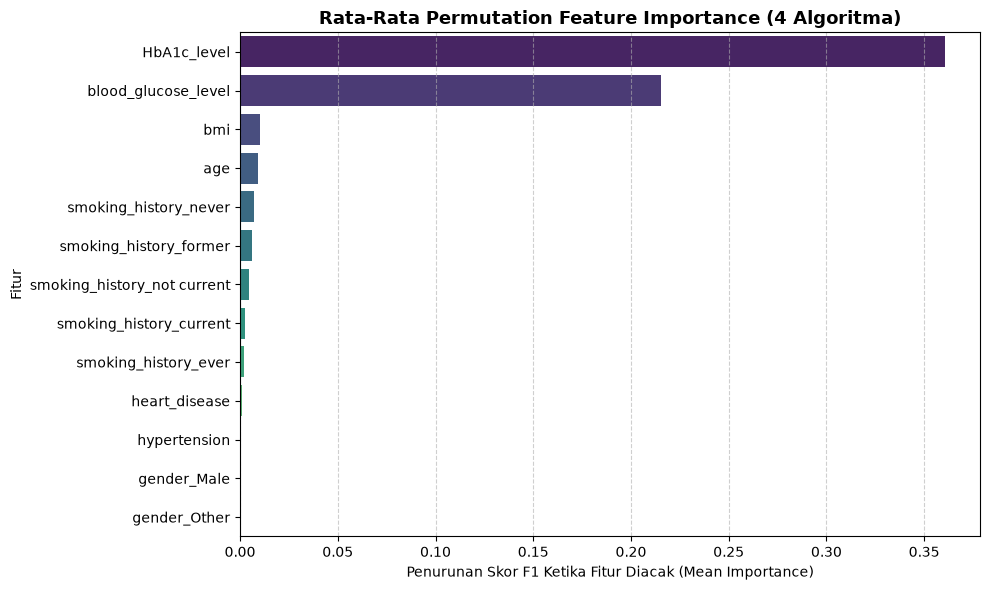

In [8]:
# Hitung Permutation Importance untuk masing-masing model
importance_records = {}

for nama, (model, _, _) in models_dict.items():
    perm = permutation_importance(
        model, X_test, y_test,
        scoring='f1',
        n_repeats=5,
        random_state=42,
        n_jobs=-1
    )
    importance_records[nama] = perm.importances_mean

# Gabungkan ke dalam satu DataFrame dan hitung rata-rata skornya
df_importance = pd.DataFrame(importance_records, index=X.columns)
df_importance['Rata_Rata_Importance'] = df_importance.mean(axis=1)
df_importance = df_importance.sort_values(by='Rata_Rata_Importance', ascending=False)

print("=== PERINGKAT FEATURE IMPORTANCE (BERDASARKAN F1-SCORE) ===")
print(df_importance.round(5))

# Visualisasi Grafik Feature Importance
plt.figure(figsize=(10, 6))
sns.barplot(
    x=df_importance['Rata_Rata_Importance'],
    y=df_importance.index,
    palette='viridis'
)
plt.title('Rata-Rata Permutation Feature Importance (4 Algoritma)', fontsize=13, fontweight='bold')
plt.xlabel('Penurunan Skor F1 Ketika Fitur Diacak (Mean Importance)')
plt.ylabel('Fitur')
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# 5. Testing Setelah pengurangan fitur

In [9]:
# 1. Tentukan jumlah fitur terbawah yang akan dibuang (misal: 2 fitur terbawah)
jumlah_fitur_dihapus = 2
fitur_terbawah = df_importance.tail(jumlah_fitur_dihapus).index.tolist()
print(f"Fitur dengan importance terbawah yang dihapus: {fitur_terbawah}")

# 2. Buat dataset latih (SMOTE) dan uji baru tanpa fitur terbawah
X_train_red = X_train_res.drop(columns=fitur_terbawah)
X_test_red = X_test.drop(columns=fitur_terbawah)

# 3. Definisikan ulang model bersih untuk dilatih pada fitur terpilih
models_reduced = {
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    'XGBoost': XGBClassifier(n_estimators=100, learning_rate=0.1, random_state=42, eval_metric='logloss', n_jobs=-1),
    'LightGBM': LGBMClassifier(n_estimators=100, learning_rate=0.1, random_state=42, verbose=-1, n_jobs=-1)
}

hasil_sesudah = []
for nama, model in models_reduced.items():
    model.fit(X_train_red, y_train_res)
    y_pred_red = model.predict(X_test_red)
    y_prob_red = model.predict_proba(X_test_red)[:, 1]
    
    hasil_sesudah.append({
        'Algoritma': nama,
        'Accuracy': accuracy_score(y_test, y_pred_red),
        'Precision': precision_score(y_test, y_pred_red),
        'Recall': recall_score(y_test, y_pred_red),
        'F1-Score': f1_score(y_test, y_pred_red),
        'ROC-AUC': roc_auc_score(y_test, y_prob_red)
    })

df_eval_sesudah = pd.DataFrame(hasil_sesudah).round(4)

print("\n=== PERBANDINGAN KINERJA MODEL (SETELAH REDUKSI FITUR) ===")
print(df_eval_sesudah.to_string(index=False))

# 4. Tabel Selisih Performa (Sesudah - Sebelum Reduksi Fitur)
df_selisih = df_eval_sesudah.set_index('Algoritma') - df_eval_sebelum.set_index('Algoritma')
print("\n=== SELISIH PERFORMA (SESUDAH - SEBELUM REDUKSI FITUR) ===")
print(df_selisih.round(4))

Fitur dengan importance terbawah yang dihapus: ['gender_Male', 'gender_Other']



=== PERBANDINGAN KINERJA MODEL (SETELAH REDUKSI FITUR) ===
    Algoritma  Accuracy  Precision  Recall  F1-Score  ROC-AUC
Decision Tree    0.9466     0.6821  0.7400    0.7098   0.8531
Random Forest    0.9563     0.7626  0.7329    0.7474   0.9602
      XGBoost    0.9646     0.8681  0.7064    0.7789   0.9725
     LightGBM    0.9642     0.8558  0.7140    0.7785   0.9737

=== SELISIH PERFORMA (SESUDAH - SEBELUM REDUKSI FITUR) ===
               Accuracy  Precision  Recall  F1-Score  ROC-AUC
Algoritma                                                    
Decision Tree    0.0006     0.0052 -0.0023    0.0017  -0.0012
Random Forest    0.0021     0.0184  0.0006    0.0092  -0.0020
XGBoost         -0.0005    -0.0046 -0.0011   -0.0026  -0.0002
LightGBM        -0.0002    -0.0067  0.0041   -0.0003   0.0002
